# 11 · Planner view: where to stage for a shift

What a planner sees before a shift starts: the production model's forecast for each of the 77 community areas, summed over the shift's 8 hours, on a map, with the 10 areas to stage in. Afterwards, once the hours are labelled, how many of the shift's crashes fell in those 10 areas (the shift's P0).

Change `DAY` and `SHIFT_START` to look at another shift (shifts start at 00:00, 08:00 and 16:00).

In [1]:
import json
import os
from datetime import timedelta

import matplotlib.pyplot as plt
import pandas as pd
import yaml

# run from the repo root, where main.py, config/ and datamart/ are
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

from utils.tables import read_table

with open("config/pipeline.yaml") as f:
    config = yaml.safe_load(f)

from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from shapely.geometry import shape

DAY, SHIFT_START = "2023-06-16", 16   # a Friday evening shift, 16:00 to 24:00
k, hours = config["evaluation"]["top_k"], config["evaluation"]["shift_hours"]
first = pd.Timestamp(f"{DAY} {SHIFT_START:02d}:00")
last = first + timedelta(hours=hours)
print(f"shift {first:%a %d %b %Y %H:%M} to {last:%H:%M}; the top {k} areas")

shift Fri 16 Jun 2023 16:00 to 00:00; the top 10 areas


## 1 · The forecast for each area

In [2]:
predictions = read_table("model_predictions", config, filters=[("date", "==", DAY), ("role", "==", "production")])
shift = predictions[(predictions["hour_start"] >= first) & (predictions["hour_start"] < last)]
print(f"production model: {', '.join(shift['model_version'].unique())}; {shift['hour_start'].nunique()} hours forecast")

with open(os.path.join(config["paths"]["reference"], config["sources"]["boundaries"]["file"])) as f:
    areas = json.load(f)["features"]
names = {int(a["properties"]["area_numbe"]): a["properties"]["community"].title() for a in areas}

forecast = shift.groupby("community_area")["predicted_count"].sum().rename("forecast").to_frame()
forecast["area"] = forecast.index.map(names)
forecast = forecast.sort_values("forecast", ascending=False)
forecast["rank"] = range(1, len(forecast) + 1)
forecast.head(k).round(2)

production model: M2_2021_12_20261027T163527; 8 hours forecast


,forecast,area,rank
community_area,,,
8,5.83,Near North Side,1
28,4.92,Near West Side,2
32,4.57,Loop,3
25,3.59,Austin,4
19,3.36,Belmont Cragin,5
22,3.35,Logan Square,6
24,3.23,West Town,7
6,3.15,Lake View,8
7,2.91,Lincoln Park,9


## 2 · The map

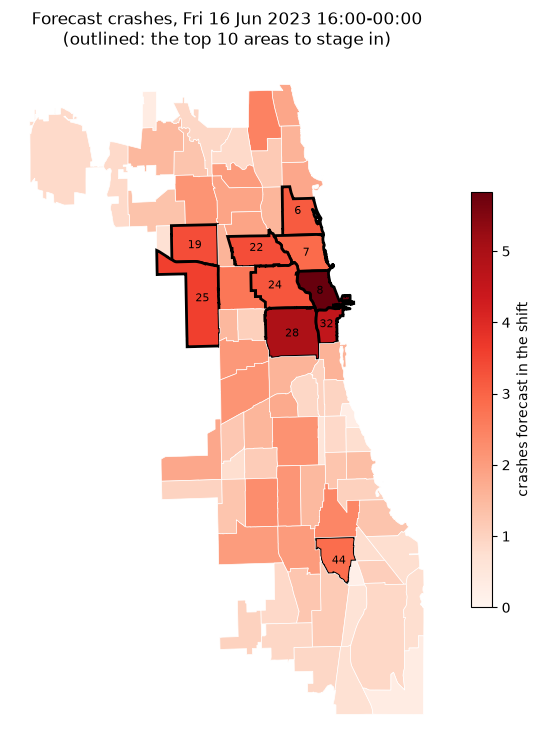

In [3]:
top = set(forecast.index[:k])
norm = Normalize(vmin=0, vmax=forecast["forecast"].max())
fig, ax = plt.subplots(figsize=(7, 9))
for a in areas:
    number = int(a["properties"]["area_numbe"])
    geometry = shape(a["geometry"])
    for polygon in getattr(geometry, "geoms", [geometry]):
        x, y = polygon.exterior.xy
        ax.fill(x, y, color=plt.cm.Reds(norm(forecast.loc[number, "forecast"])),
                edgecolor="black" if number in top else "white", linewidth=2 if number in top else 0.5)
    if number in top:
        point = geometry.representative_point()
        ax.annotate(str(number), (point.x, point.y), ha="center", va="center", fontsize=8)
fig.colorbar(ScalarMappable(norm=norm, cmap="Reds"), ax=ax, shrink=0.6, label="crashes forecast in the shift")
ax.set_title(f"Forecast crashes, {first:%a %d %b %Y %H:%M}-{last:%H:%M}\n(outlined: the top {k} areas to stage in)")
ax.set_axis_off()
plt.show()

## 3 · How did the shift go?

The labels: crashes that occurred in the shift's hours, as the label store has them. P0 for this one shift: the share of them in the 10 outlined areas.

In [4]:
labels = read_table("label_store", config, filters=[("date", "==", DAY)])
labels = labels[(labels["hour_start"] >= first) & (labels["hour_start"] < last)]
labels = labels.sort_values("label_snapshot_date").drop_duplicates(["community_area", "hour_start"], keep="last")
actual = labels.groupby("community_area")["crash_count"].sum()
forecast["actual"] = actual.reindex(forecast.index, fill_value=0)
caught = forecast.loc[forecast.index[:k], "actual"].sum()
print(f"crashes in the shift: {forecast['actual'].sum()}; in the top {k} areas: {caught} "
      f"(P0 {caught / forecast['actual'].sum():.2f}); forecast citywide: {forecast['forecast'].sum():.1f}")
forecast.head(k).round(2)

crashes in the shift: 112; in the top 10 areas: 27 (P0 0.24); forecast citywide: 126.0


,forecast,area,rank,actual
community_area,,,,
8,5.83,Near North Side,1,2
28,4.92,Near West Side,2,3
32,4.57,Loop,3,5
25,3.59,Austin,4,3
19,3.36,Belmont Cragin,5,1
22,3.35,Logan Square,6,2
24,3.23,West Town,7,4
6,3.15,Lake View,8,2
7,2.91,Lincoln Park,9,1
